# Deep Deterministic Policy Gradient (DDPG) on Pendulum with Stable-Baselines3

In [1]:
import gymnasium as gym
import numpy as np
import time
from matplotlib import pyplot as plt

from stable_baselines3 import DDPG
from stable_baselines3.common.evaluation import evaluate_policy
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.noise import NormalActionNoise

## Configuration

These are the hyperparameters tuned for Pendulum by the [RL Baselines3 Zoo](https://github.com/DLR-RM/rl-baselines3-zoo/blob/master/hyperparams/ddpg.yml), written out so that they are easy to inspect and change.

In [2]:
# Training configuration
ENV_ID = "Pendulum-v1"
TOTAL_TIMESTEPS = 20_000
LEARNING_STARTS = 10_000   # random steps that fill the replay buffer before training
BUFFER_SIZE = 200_000      # capacity of the replay buffer
GAMMA = 0.98               # discount factor
LEARNING_RATE = 0.001      # actor and critic
NOISE_STD = 0.1            # standard deviation of the exploration noise
HIDDEN_SIZES = [400, 300]  # hidden layers of the actor and of the critic
N_EVAL_EPISODES = 100

SEED = 42

## Environment

`Pendulum-v1`: a pendulum hangs from a fixed pivot and has to be swung up and kept upright. The observation is $[\cos\theta, \sin\theta, \dot\theta]$, where $\theta = 0$ is the upright position, and the action is a **continuous** torque $u \in [-2, 2]$. The reward at every step is

$$r = -\left(\theta^2 + 0.1\,\dot\theta^2 + 0.001\,u^2\right), \qquad \theta \in [-\pi, \pi],$$

so it is $0$ only when the pendulum is upright, still and without torque. Episodes never terminate; they are truncated after 200 steps. Gymnasium gives no reward threshold, so we use a mean return of $-200$ as an informal reference for a policy that swings the pendulum up and balances it.

DDPG is off-policy and learns from a replay buffer, so one environment is enough. `Monitor` records the return of every training episode.

In [3]:
env = Monitor(gym.make(ENV_ID))

print("Observation space:", env.observation_space)
print("Action space:", env.action_space)
print("Maximum episode steps:", env.spec.max_episode_steps)
print("Reward threshold:", env.spec.reward_threshold)

Observation space: Box([-1. -1. -8.], [1. 1. 8.], (3,), float32)
Action space: Box(-2.0, 2.0, (1,), float32)
Maximum episode steps: 200
Reward threshold: None


## DDPG agent

DDPG explores by adding Gaussian noise to the action of its deterministic actor, $a_t = \mu(s_t;\theta) + \varepsilon_t$ with $\varepsilon_t \sim \mathcal{N}(0, \sigma^2)$, clipped to the torque limits. The noise is passed to the constructor as `action_noise`. With `verbose=1`, SB3 prints a table of training statistics during training.

In [4]:
n_actions = env.action_space.shape[0]
action_noise = NormalActionNoise(
    mean=np.zeros(n_actions),
    sigma=NOISE_STD * np.ones(n_actions),
)

model = DDPG(
    "MlpPolicy",
    env,
    learning_rate=LEARNING_RATE,
    buffer_size=BUFFER_SIZE,
    learning_starts=LEARNING_STARTS,
    gamma=GAMMA,
    action_noise=action_noise,
    policy_kwargs=dict(net_arch=HIDDEN_SIZES),
    verbose=1,
    seed=SEED,
    device="cpu",
)

print(model.policy)

Using cpu device
Wrapping the env in a DummyVecEnv.
TD3Policy(
  (actor): Actor(
    (features_extractor): FlattenExtractor(
      (flatten): Flatten(start_dim=1, end_dim=-1)
    )
    (mu): Sequential(
      (0): Linear(in_features=3, out_features=400, bias=True)
      (1): ReLU()
      (2): Linear(in_features=400, out_features=300, bias=True)
      (3): ReLU()
      (4): Linear(in_features=300, out_features=1, bias=True)
      (5): Tanh()
    )
  )
  (actor_target): Actor(
    (features_extractor): FlattenExtractor(
      (flatten): Flatten(start_dim=1, end_dim=-1)
    )
    (mu): Sequential(
      (0): Linear(in_features=3, out_features=400, bias=True)
      (1): ReLU()
      (2): Linear(in_features=400, out_features=300, bias=True)
      (3): ReLU()
      (4): Linear(in_features=300, out_features=1, bias=True)
      (5): Tanh()
    )
  )
  (critic): ContinuousCritic(
    (features_extractor): FlattenExtractor(
      (flatten): Flatten(start_dim=1, end_dim=-1)
    )
    (qf0): Seque

The printout shows four networks:

* `actor` is the deterministic policy $\mu(s;\theta)$. It maps the 3 observations to one action; the final `Tanh` keeps the output in $[-1, 1]$, and SB3 rescales it to the torque range $[-2, 2]$.
* `critic` is the action-value function $q(s, a; w)$. Unlike the critic of A2C, it receives the state **and** the action ($3 + 1 = 4$ inputs).
* `actor_target` and `critic_target` are slowly moving copies, $\theta^-$ and $w^-$, used to compute the learning targets, as the target network of DQN. After every update they take a small step towards the trained networks, $w^- \leftarrow \tau w + (1-\tau)\, w^-$ with $\tau = 0.005$, and the same for $\theta^-$.

## Training

During the first `LEARNING_STARTS` steps the agent acts at random to fill the replay buffer. After that, at every environment step it stores the transition and samples a minibatch of 256 transitions from the buffer to update the critic and the actor:

* **Critic**: minimize $\big(y - q(s, a; w)\big)^2$ with the target $y = r + \gamma\, q\big(s', \mu(s';\theta^-); w^-\big)$, calculated with the target networks;
* **Actor**: maximize $q\big(s, \mu(s;\theta); w\big)$. By the chain rule, this is the **deterministic policy gradient**

$$\nabla_\theta J \approx \frac{1}{B}\sum_{i=1}^{B} \nabla_a q(s_i, a; w)\big|_{a=\mu(s_i;\theta)}\; \nabla_\theta \mu(s_i;\theta).$$

For off-policy algorithms, `log_interval` counts **episodes**: 20,000 steps are 100 episodes of 200 steps, and we ask for a table every 20 episodes. The most useful entries are:

* `rollout/ep_rew_mean`: mean return of the last 100 training episodes (including the random ones);
* `train/critic_loss`: the squared error of the critic with respect to its targets;
* `train/actor_loss`: $-q\big(s, \mu(s;\theta); w\big)$ averaged over the minibatch, which decreases as the actor finds actions with higher values.

In [5]:
start_time = time.time()
model.learn(total_timesteps=TOTAL_TIMESTEPS, log_interval=20)
training_minutes = (time.time() - start_time) / 60

print(f"Training time: {training_minutes:.2f} minutes")
print(f"Environment steps: {model.num_timesteps}")
print(f"Updates: {model._n_updates}")

----------------------------------
| rollout/           |           |
|    ep_len_mean     | 200       |
|    ep_rew_mean     | -1.21e+03 |
| time/              |           |
|    episodes        | 20        |
|    fps             | 14372     |
|    time_elapsed    | 0         |
|    total_timesteps | 4000      |
----------------------------------
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 200      |
|    ep_rew_mean     | -1.2e+03 |
| time/              |          |
|    episodes        | 40       |
|    fps             | 14149    |
|    time_elapsed    | 0        |
|    total_timesteps | 8000     |
---------------------------------
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 200      |
|    ep_rew_mean     | -1.2e+03 |
| time/              |          |
|    episodes        | 60       |
|    fps             | 1728     |
|    time_elapsed    | 6        |
|    total_timesteps | 12000    |
| tr

## Learning curve

`Monitor` recorded the return and the length of every training episode. The dotted line marks the end of the random steps.

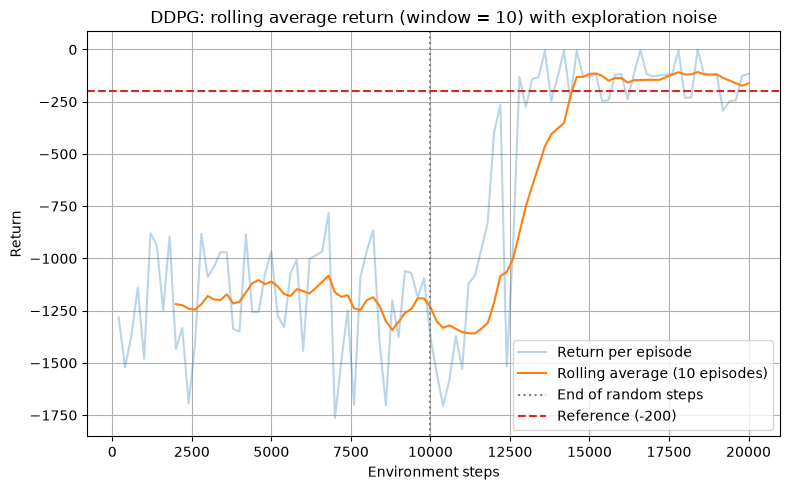

Training episodes: 100


In [6]:
episode_returns = np.array(env.get_episode_rewards())
episode_end_steps = np.cumsum(env.get_episode_lengths())

window = 10
rolling_returns = np.convolve(episode_returns, np.ones(window) / window, mode="valid")

plt.figure(figsize=(8, 5))
plt.plot(episode_end_steps, episode_returns, alpha=0.3, label="Return per episode")
plt.plot(episode_end_steps[window - 1:], rolling_returns, label=f"Rolling average ({window} episodes)")
plt.axvline(LEARNING_STARTS, color="gray", linestyle=":", label="End of random steps")
plt.axhline(-200, color="tab:red", linestyle="--", label="Reference (-200)")
plt.xlabel("Environment steps")
plt.ylabel("Return")
plt.title(f"DDPG: rolling average return (window = {window}) with exploration noise")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Training episodes: {len(episode_returns)}")

## Evaluate the policy

`evaluate_policy` from SB3 plays complete episodes and returns their returns. The actor of DDPG is deterministic and the exploration noise is only added during training, so there is a single evaluation: the action $\mu(s;\theta)$, over 100 episodes from an environment seeded with `SEED + 1000`.

In [7]:
eval_env = Monitor(gym.make(ENV_ID))
eval_env.reset(seed=SEED + 1000)  # later resets continue from this seed
returns, lengths = evaluate_policy(
    model,
    eval_env,
    n_eval_episodes=N_EVAL_EPISODES,
    deterministic=True,
    return_episode_rewards=True,
)
eval_env.close()
returns = np.array(returns)

print(
    f"greedy: mean {returns.mean():7.1f} | std {returns.std():6.1f} | "
    f"min {returns.min():7.1f} | max {returns.max():7.1f} | "
    f"reference (mean >= -200): {returns.mean() >= -200}"
)

greedy: mean  -163.2 | std   90.0 | min  -373.0 | max    -1.8 | reference (mean >= -200): True


## One greedy rollout

To see the swing-up, we start the pendulum hanging straight down and at rest, $\theta = \pi$ and $\dot\theta = 0$, by setting the state of the simulator directly (`rollout_env.unwrapped.state`). We plot the angle $\theta = \operatorname{atan2}(\sin\theta, \cos\theta)$, where $+180°$ and $-180°$ are the same downward position, together with the applied torque.

The motor is too weak to lift the pendulum directly, so the actor first pushes with the maximum torque in one direction and then in the other to gain energy, and then holds the pendulum near $\theta = 0$. Once it is upright, the torque switches rapidly between large positive and negative values: the reward penalizes the torque only weakly ($0.001\,u^2$), so nothing pushes the deterministic actor towards small, smooth torques.

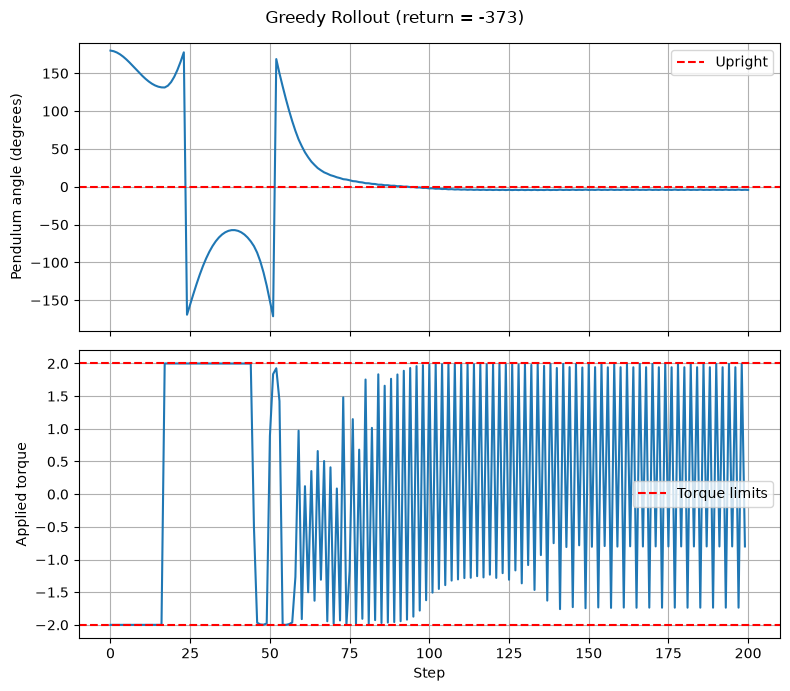

Rollout return: -373.3
Rollout steps:  200


In [8]:
rollout_env = gym.make(ENV_ID)
rollout_env.reset(seed=SEED + 2000)
rollout_env.unwrapped.state = np.array([np.pi, 0.0])  # hanging straight down, at rest
state = np.array([np.cos(np.pi), np.sin(np.pi), 0.0], dtype=np.float32)
rollout_states = [state.copy()]
rollout_torques = []
rollout_return = 0.0

for step in range(rollout_env.spec.max_episode_steps):
    action, _ = model.predict(state, deterministic=True)
    state, reward, terminated, truncated, info = rollout_env.step(action)
    rollout_states.append(state.copy())
    rollout_torques.append(action[0])
    rollout_return += reward

    if terminated or truncated:
        break

rollout_states = np.array(rollout_states)
angles = np.degrees(np.arctan2(rollout_states[:, 1], rollout_states[:, 0]))
time_steps = np.arange(len(rollout_states))

fig, axes = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
axes[0].plot(time_steps, angles)
axes[0].axhline(0.0, color="red", linestyle="--", label="Upright")
axes[0].set_ylabel("Pendulum angle (degrees)")
axes[0].set_ylim(-190, 190)
axes[0].grid(True)
axes[0].legend()

axes[1].plot(time_steps[:-1], rollout_torques)
axes[1].axhline(-2.0, color="red", linestyle="--", label="Torque limits")
axes[1].axhline(2.0, color="red", linestyle="--")
axes[1].set_xlabel("Step")
axes[1].set_ylabel("Applied torque")
axes[1].grid(True)
axes[1].legend()

fig.suptitle(f"Greedy Rollout (return = {rollout_return:.0f})")
fig.tight_layout()
plt.show()

print(f"Rollout return: {rollout_return:.1f}")
print(f"Rollout steps:  {len(rollout_states) - 1}")

## Save the trained agent

`model.save` writes a `.zip` file with the actor, the critic, their target copies and the hyperparameters (not the replay buffer), and `DDPG.load` rebuilds the whole agent from it. We check that the reloaded agent chooses the same action.

To watch the saved agent, run from this folder:

```
python run_ddpg_pendulum_policy.py --episodes 3
```

In [9]:
MODEL_PATH = "ddpg_pendulum_policy"
model.save(MODEL_PATH)  # writes ddpg_pendulum_policy.zip

# Check that the saved agent can be loaded.
check_model = DDPG.load(MODEL_PATH, device="cpu")

check_state, info = rollout_env.reset(seed=SEED + 3000)
original_action, _ = model.predict(check_state, deterministic=True)
reloaded_action, _ = check_model.predict(check_state, deterministic=True)

print("Saved and reloaded:", MODEL_PATH + ".zip")
print("Actions match:", bool(np.allclose(original_action, reloaded_action)))
env.close()
rollout_env.close()

Saved and reloaded: ddpg_pendulum_policy.zip
Actions match: True
